# 05 · Build the dataset: merge X and Y, split train / val / test (GreenPath)

**What this step does**: merge the tables produced by the earlier steps into one trainable "xy table", filter out cells of insufficient quality, split the data by **spatial block**, and register a version for this dataset.

| | Path (relative to the data root) |
|---|---|
| Input: cell master table (with aerial-tile paths) | `processed/cells.parquet` (from 01, 02) |
| Input: OSM / WorldCover features | `processed/osm_features.parquet` (from 03) |
| Input: labels Y | `processed/labels_cell.parquet` (from 04) |
| Output: **master table** | `datasets/{version}/dataset.parquet` |
| Output: views pre-cut by split | `datasets/{version}/train.parquet`, `val.parquet`, `test.parquet` |
| Output: column grouping | `datasets/{version}/schema.json` |
| Output: provenance and version record | `datasets/{version}/manifest.json` |
| Output: dataset card | `datasets/{version}/DATASET_CARD.md` |
| Output: run record | `runs/{timestamp}/05_build_dataset_manifest.json` |

**Dataset versions are "frozen"**: if the version already exists, by default the **existing version is used as it is and not regenerated**; the check plots and tables are still shown, but no file is written (only `OVERWRITE = True` regenerates and overwrites). When data or labels change, bump the version `v1` → `v2`, so any model can state exactly which version of the data it was trained on.

**How the split works (the most important part)**: neighboring cells are almost identical, so a random split would inflate the test score (spatial leakage). Therefore:
1. First cut the map into H3 **blocks** (default resolution 8, about 0.7 km²);
2. Assign **whole blocks** to train / val / test, so all cells of one block are always in the same split;
3. Drop a ring of train / val cells right next to the test blocks (the **buffer**) to prevent leakage across block borders;
4. In addition, assign the train+val blocks to 5 folds (the `fold` column) for grouped cross-validation when the sample is small; when there is more data, simply stop using this column;
5. If a second city is added later, set `TEST_CITIES` to it and the **whole city becomes the test set**, which is a true cross-city test.

**The test set is looked at only once, for the final report**; all tuning uses train / val or cross-validation.

## 1. Install dependencies (runs only on Colab)

In [1]:
import sys, subprocess
if "google.colab" in sys.modules:      # Install automatically only on Colab; locally, install the dependencies beforehand
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "h3>=4", "pandas", "pyarrow", "gcsfs", "matplotlib", "tqdm", "fsspec"], check=True)

## 2. Configuration
- `DATASET_VERSION`: the name of this dataset version. **If any input or parameter changes, bump the version.**
- `BLOCK_RES`: block size (H3 resolution). 8 ≈ 0.7 km²; larger blocks (a smaller number) leak less but give fewer blocks.
- `SPLIT_RATIOS`: the share of cells in train / val / test (assigned by block, so only approximate).
- `BUFFER_RINGS`: how many rings of cells to drop around the test blocks. `0` = none.
- `N_FOLDS`: how many folds to split train+val into.
- `MAX_YEAR_GAP`: cells whose street-photo year (the midpoint between the earliest and latest photo of the cell) differs from the aerial-tile year by more than this are dropped.
- `MIN_LABELED_DIMS`: a cell is kept only if at least this many dimensions have a label that is not missing.
- `TEST_CITIES`: when not empty, all cells of these cities form the test set (cross-city test), and the remaining cities are split into train / val by block.
- `OVERWRITE`: when `False` (default), an existing version is used as it is and not regenerated; when `True`, the version is regenerated and the existing one with the same name is overwritten (normally leave it off). If the current configuration differs from the parameters of the existing version, a warning is printed.

In [2]:
DATASET_VERSION = "v1"
BLOCK_RES = 8
SPLIT_RATIOS = (0.70, 0.15, 0.15)       # train, val, test
BUFFER_RINGS = 1
N_FOLDS = 5
MAX_YEAR_GAP = 3
MIN_LABELED_DIMS = 1
TEST_CITIES = []                        # e.g. ["providence"]
SEED = 42
OVERWRITE = False

STORAGE = "local"                              # "local" | "gcs" | "drive"
GCS_ROOT = "gs://greenpath-data"
DRIVE_ROOT = "/content/drive/MyDrive/greenpath-data"
LOCAL_ROOT = "./data"

## 3. Connect to storage and read the three tables

In [3]:
import os, io, json, datetime
import fsspec
import pandas as pd

STORAGE_OPTS = {}
if STORAGE == "gcs":
    try:
        from google.colab import auth
        auth.authenticate_user()                 # On Colab, log in here; locally, first run gcloud auth application-default login
    except ImportError:
        pass
    ROOT = GCS_ROOT
    STORAGE_OPTS = {"token": "google_default"}
    fs = fsspec.filesystem("gcs", **STORAGE_OPTS)
elif STORAGE == "drive":
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = DRIVE_ROOT
    fs = fsspec.filesystem("file")
else:
    ROOT = os.environ.get("GREENPATH_ROOT", LOCAL_ROOT)   # later, containers can set the data directory through an environment variable
    fs = fsspec.filesystem("file")

def path(*parts):
    # build the full path under the data root, e.g. path("processed", "cells.parquet")
    return "/".join([ROOT.rstrip("/"), *parts])

def makedirs(p):
    if STORAGE != "gcs":            # GCS has no real directories, so there is nothing to create
        os.makedirs(p, exist_ok=True)

def read_parquet(p):
    return pd.read_parquet(p, storage_options=STORAGE_OPTS or None)

def write_parquet(df, p):
    df.to_parquet(p, index=False, storage_options=STORAGE_OPTS or None)

def write_manifest(manifest, name):
    run_ts = datetime.datetime.utcnow().strftime("%Y-%m-%dT%H-%M")
    makedirs(path("runs", run_ts))
    with fs.open(path("runs", run_ts, name), "w") as f:
        json.dump(manifest, f, indent=2, ensure_ascii=False)
    return manifest

try:                                          # use a system CJK font so any CJK text in charts renders correctly
    import matplotlib
    matplotlib.rcParams["font.sans-serif"] = ["PingFang SC", "Heiti SC", "Arial Unicode MS", "Noto Sans CJK SC",
                                              "Microsoft YaHei", "SimHei", "DejaVu Sans"]
    matplotlib.rcParams["axes.unicode_minus"] = False
except ImportError:
    pass

now_iso = lambda: datetime.datetime.utcnow().isoformat(timespec="seconds") + "Z"
print("Data root:", ROOT)

Data root: ./data


In [4]:
import numpy as np, hashlib, h3
import matplotlib.pyplot as plt

DIMS = ["traffic_intensity", "quietness", "shade", "naturalness",
        "scenic_appeal", "historic_character", "liveliness", "visual_openness"]
OUT_DIR = f"datasets/{DATASET_VERSION}"
EXISTS = fs.exists(path(OUT_DIR, "manifest.json"))
REGENERATE = (not EXISTS) or OVERWRITE          # regenerate only if the version does not exist yet, or overwriting was explicitly requested

if REGENERATE:
    if EXISTS:
        print(f"OVERWRITE = True: regenerating dataset {DATASET_VERSION} (overwriting the existing version of the same name)")
    cells = read_parquet(path("processed", "cells.parquet"))
    osm = read_parquet(path("processed", "osm_features.parquet"))
    labels = read_parquet(path("processed", "labels_cell.parquet"))
    with fs.open(path("processed", "labels_meta.json"), "r") as f:
        labels_meta = json.load(f)
    shown_block_res, shown_buffer = BLOCK_RES, BUFFER_RINGS
    print(f"cells {len(cells)} · OSM features {len(osm)} · labels {len(labels)}")
    print(f"Labels from: {labels_meta['model']} · prompt {labels_meta['prompt_version']} · estimated cost ${labels_meta['est_cost_usd']}")
else:
    # reuse the existing version: read the master table, version record, and column grouping; the checks below are still shown, but no file is written
    out = read_parquet(path(OUT_DIR, "dataset.parquet"))
    with fs.open(path(OUT_DIR, "manifest.json"), "r") as f:
        manifest = json.load(f)
    with fs.open(path(OUT_DIR, "schema.json"), "r") as f:
        schema = json.load(f)
    df, funnel = out, list(manifest["funnel"].items())
    shown_block_res, shown_buffer = manifest["params"]["block_res"], manifest["params"]["buffer_rings"]
    print(f"Dataset {DATASET_VERSION} already exists (frozen version) and is used as it is, not regenerated. To regenerate, set OVERWRITE = True; if data or parameters changed, bump the version (e.g. v2).")
    print(f"Existing version: {len(out)} cells; created at {manifest['created_at']}")
    now = {"block_res": BLOCK_RES, "split_ratios": list(SPLIT_RATIOS), "buffer_rings": BUFFER_RINGS, "n_folds": N_FOLDS,
           "max_year_gap": MAX_YEAR_GAP, "min_labeled_dims": MIN_LABELED_DIMS, "test_cities": list(TEST_CITIES)}
    diffs = {k: (manifest["params"].get(k), v) for k, v in now.items() if json.loads(json.dumps(manifest["params"].get(k))) != json.loads(json.dumps(v))}
    if diffs:
        print("⚠ The current configuration differs from the existing version, but it was not regenerated (existing value, current value):", diffs)

Dataset v1 already exists (frozen version) and is used as it is, not regenerated. To regenerate, set OVERWRITE = True; if data or parameters changed, bump the version (e.g. v2).
Existing version: 1012 cells; created at 2026-10-13T00:59:50Z


## 4. Merge
Join the three tables side by side on `h3_index`. The columns fall into three groups:
- **Image input**: `tile_path` and friends (the aerial tile itself is not put into the table, only its relative path);
- **Tabular input**: the OSM / WorldCover features;
- **Labels Y**: 8 dimensions (0–1, missing = NaN) and their standard deviations.

In [5]:
if REGENERATE:
    osm_cols = [c for c in osm.columns if c not in ("cell_id", "h3_index", "updated_at")]
    cat_cols = [c for c in osm_cols if not pd.api.types.is_numeric_dtype(osm[c])]   # e.g. wc_dominant (a category, not a number)
    tab_cols = [c for c in osm_cols if c not in cat_cols]
    std_cols = [f"{d}_std" for d in DIMS]

    df = (cells.drop(columns=["updated_at"], errors="ignore")
          .merge(osm.drop(columns=["cell_id", "updated_at"], errors="ignore"), on="h3_index", how="left", validate="1:1")
          .merge(labels[["h3_index", "n_usable", *DIMS, *std_cols, "prompt_version", "model"]]
                 .rename(columns={"prompt_version": "label_prompt_version", "model": "label_model"}),
                 on="h3_index", how="left", validate="1:1"))
    print(f"After merging: {len(df)} rows, {df.shape[1]} columns; {len(tab_cols)} tabular features, categorical features {cat_cols}")

## 5. Filter
Every step prints "how many cells are left". The reasons for dropping cells are written into the dataset card.

In [6]:
if REGENERATE:
    funnel = [("merged cells", len(df))]
    def step(name, mask):
        global df
        df = df[mask(df)].reset_index(drop=True)
        funnel.append((name, len(df)))

    step("aerial tile usable", lambda d: d.tile_ok.fillna(False).astype(bool))
    step(f"at least {MIN_LABELED_DIMS} labeled dimension(s)", lambda d: d[DIMS].notna().sum(axis=1) >= MIN_LABELED_DIMS)
    yr = lambda s: pd.to_datetime(s, format="%Y-%m").dt.year
    df["street_year_mid"] = (yr(df.capture_min) + yr(df.capture_max)) / 2
    df["year_gap"] = (df.naip_year.astype(float) - df.street_year_mid).abs()
    step(f"aerial vs street-photo year gap ≤ {MAX_YEAR_GAP}", lambda d: d.year_gap <= MAX_YEAR_GAP)
    step("OSM features complete", lambda d: d.road_total_m.notna())

    for name, n in funnel:
        print(f"{name:<32}{n:>8,}")

## 6. Split: blocks → train / val / test, buffer, cross-validation folds
The three functions below have no side effects and can be tested on their own:
- `assign_splits`: assigns train / val / test by block (greedily reaching each target share of cells);
- `apply_buffer`: drops the train / val cells right next to the test set;
- `assign_folds`: splits the train+val blocks into `N_FOLDS` folds with cell counts as balanced as possible.

In [7]:
def assign_splits(d, ratios, test_cities, seed):
    # test cities given explicitly: every cell of those cities goes straight to test (judged by the cell's own city); the remaining cells are assigned by block
    rng = np.random.default_rng(seed)
    is_test_city = d.city.isin(test_cities) if test_cities else pd.Series(False, index=d.index)
    blocks = d[~is_test_city].groupby("block_id").size().rename("n").reset_index()
    total = blocks.n.sum()
    if test_cities:
        test_target, val_target = 0, total * ratios[1] / (ratios[0] + ratios[1])
    else:
        test_target, val_target = total * ratios[2], total * ratios[1]
    split_of, acc_t, acc_v = {}, 0, 0
    for i in rng.permutation(len(blocks)):
        b, n = blocks.iloc[i].block_id, blocks.iloc[i].n
        if acc_t < test_target:
            split_of[b] = "test"; acc_t += n
        elif acc_v < val_target:
            split_of[b] = "val"; acc_v += n
        else:
            split_of[b] = "train"
    return d.block_id.map(split_of).where(~is_test_city, "test")

def apply_buffer(d, rings):
    # drop train / val cells within `rings` rings of any test cell; test cells stay untouched
    if rings <= 0:
        return d.index
    test_set = set(d.loc[d.split == "test", "h3_index"])
    drop = [i for i, r in d[d.split != "test"].iterrows()
            if any(n in test_set for n in h3.grid_disk(r.h3_index, rings))]
    return d.index.difference(drop)

def assign_folds(d, n_folds, seed):
    # fold assignment only for train+val blocks; greedily put each block into the fold that currently has the fewest cells
    rng = np.random.default_rng(seed + 1)
    b = d[d.split.isin(["train", "val"])].groupby("block_id").size()
    b = b.iloc[rng.permutation(len(b))].sort_values(ascending=False, kind="stable")
    load = np.zeros(n_folds, dtype=int); fold_of = {}
    for blk, n in b.items():
        k = int(load.argmin()); fold_of[blk] = k; load[k] += n
    return d.block_id.map(fold_of).astype("Int64")

In [8]:
if REGENERATE:
    df["block_id"] = [h3.cell_to_parent(i, BLOCK_RES) for i in df.h3_index]
    df["split"] = assign_splits(df, SPLIT_RATIOS, TEST_CITIES, SEED)
    n_before = len(df)
    df = df.loc[apply_buffer(df, BUFFER_RINGS)].reset_index(drop=True)
    funnel.append((f"buffer: dropped {BUFFER_RINGS} ring(s) of cells next to the test set", len(df)))
    df["fold"] = assign_folds(df, N_FOLDS, SEED)

    # check: no block appears in two splits
    leak = df.groupby("block_id").split.nunique()
    assert (leak == 1).all(), "Some block belongs to more than one split!"
    print(f"{df.block_id.nunique()} blocks in total; the buffer dropped {n_before - len(df)} cells")

summary = df.groupby("split").agg(n_cells=("h3_index", "size"), n_blocks=("block_id", "nunique")).reindex(["train", "val", "test"]).fillna(0).astype(int)
summary["share"] = (summary.n_cells / summary.n_cells.sum()).round(2)
summary

,n_cells,n_blocks,share
split,,,
train,651,41,0.64
val,173,10,0.17
test,188,12,0.19


## 7. Check that the split is reasonable
- **Map**: the three colors should appear in contiguous patches, not scattered and mixed;
- **Label means**: the means of the splits should not differ much; a large difference means some split happened to receive a special area;
- **Missing rate**: the share of missing labels for each dimension.

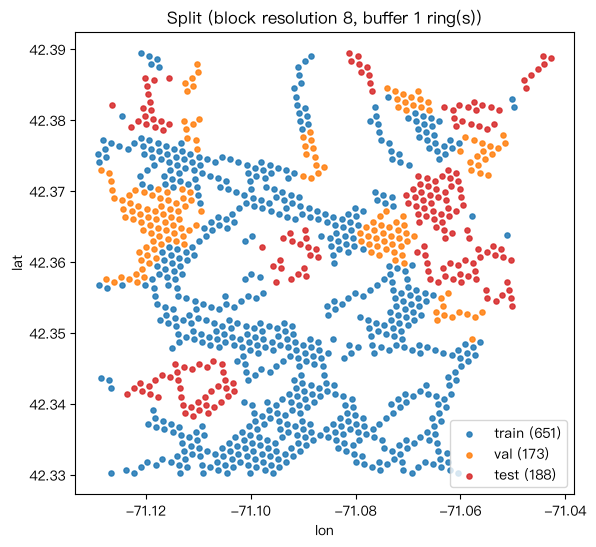

,traffic_intensity,quietness,shade,naturalness,scenic_appeal,historic_character,liveliness,visual_openness
split,,,,,,,,
train,0.57,0.40,0.27,0.28,0.45,0.40,0.22,0.49
val,0.47,0.46,0.24,0.32,0.48,0.40,0.15,0.54
test,0.59,0.36,0.26,0.22,0.40,0.34,0.21,0.50
missing rate (overall),0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


In [9]:
fig, ax = plt.subplots(figsize=(8, 6))
for s, c in [("train", "tab:blue"), ("val", "tab:orange"), ("test", "tab:red")]:
    x = df[df.split == s]
    ax.scatter(x.lon, x.lat, s=14, c=c, label=f"{s} ({len(x)})", alpha=.85)
ax.set_aspect(1 / np.cos(np.radians(df.lat.mean()))); ax.legend(); ax.set_xlabel("lon"); ax.set_ylabel("lat")
ax.set_title(f"Split (block resolution {shown_block_res}, buffer {shown_buffer} ring(s))")
plt.show()

chk = df.groupby("split")[DIMS].mean().reindex(["train", "val", "test"]).round(2)
chk.loc["missing rate (overall)"] = df[DIMS].isna().mean().round(2)
chk

## 8. Write the dataset
- `dataset.parquet`: all rows, with the `split`, `block_id`, and `fold` columns;
- `train / val / test.parquet`: views pre-cut by `split`, read directly by training scripts;
- `schema.json`: column groups (identifiers, image, tabular features, categorical features, labels, label quality, provenance); training code picks columns from it instead of hard-coding them;
- `manifest.json`: hashes of the input files, prompt version and hash, OSM snapshot date, filter conditions, split parameters.
Numeric columns are stored as float32.

In [10]:
if REGENERATE:
    id_cols = ["cell_id", "h3_index", "city", "lat", "lon"]
    split_cols = ["split", "block_id", "fold"]
    image_cols = ["tile_path", "naip_year", "ground_m", "tile_px"]
    quality_cols = ["n_images", "n_usable", "capture_min", "capture_max", "year_gap", *std_cols]
    prov_cols = ["label_model", "label_prompt_version", "dataset_version"]
    df["dataset_version"] = DATASET_VERSION

    order = id_cols + split_cols + image_cols + tab_cols + cat_cols + DIMS + quality_cols + prov_cols
    out = df[order].copy()
    for c in tab_cols + DIMS + std_cols + ["year_gap"]:
        out[c] = out[c].astype("float32")
    out["fold"] = out.fold.astype("Int64")
    out = out.sort_values(["split", "cell_id"]).reset_index(drop=True)

    makedirs(path(OUT_DIR))
    write_parquet(out, path(OUT_DIR, "dataset.parquet"))
    for s in ["train", "val", "test"]:
        write_parquet(out[out.split == s].reset_index(drop=True), path(OUT_DIR, f"{s}.parquet"))

    schema = {"id": id_cols, "split": split_cols, "image": image_cols, "tabular": tab_cols, "categorical": cat_cols,
              "targets": DIMS, "target_std": std_cols, "quality": quality_cols, "provenance": prov_cols,
              "notes": "targets take values 0–1, missing = NaN; tile_path is relative to the data root; fold has values only for train/val"}
    with fs.open(path(OUT_DIR, "schema.json"), "w") as f:
        json.dump(schema, f, indent=2, ensure_ascii=False)
    print(f"Wrote {OUT_DIR}/: {len(out)} rows × {out.shape[1]} columns")
out.groupby("split").size().reindex(["train", "val", "test"])

split
train    651
val      173
test     188
dtype: int64

## 9. Version record and dataset card

In [11]:
if REGENERATE:
    def sha256(rel):
        h = hashlib.sha256()
        with fs.open(path(rel), "rb") as f:
            for chunk in iter(lambda: f.read(1 << 20), b""):
                h.update(chunk)
        return h.hexdigest()[:16]

    osm_meta = {}
    try:
        pbfs = [p for p in fs.ls(path("raw", "osm")) if str(p).endswith(".meta.json")]
        if pbfs:
            with fs.open(pbfs[0], "r") as f:
                osm_meta = json.load(f)
    except Exception:
        pass

    manifest = {
        "dataset_version": DATASET_VERSION, "created_at": now_iso(), "seed": SEED,
        "inputs": {rel: sha256(rel) for rel in ["processed/cells.parquet", "processed/osm_features.parquet", "processed/labels_cell.parquet"]},
        "labels": {k: labels_meta.get(k) for k in ["model", "prompt_version", "prompt_sha", "thinking_budget", "temperature", "images_scored", "est_cost_usd"]},
        "osm_snapshot": osm_meta,
        "params": {"block_res": BLOCK_RES, "split_ratios": SPLIT_RATIOS, "buffer_rings": BUFFER_RINGS, "n_folds": N_FOLDS,
                   "max_year_gap": MAX_YEAR_GAP, "min_labeled_dims": MIN_LABELED_DIMS, "test_cities": TEST_CITIES},
        "funnel": dict(funnel),
        "counts": {s: int((out.split == s).sum()) for s in ["train", "val", "test"]},
        "cities": sorted(out.city.unique().tolist()),
        "label_validation": "pending (E1: human annotation not yet done)",
    }
    with fs.open(path(OUT_DIR, "manifest.json"), "w") as f:
        json.dump(manifest, f, indent=2, ensure_ascii=False)

    funnel_en = ["merged cells", "aerial tile usable", f"at least {MIN_LABELED_DIMS} labeled dimension(s)",
                 f"aerial vs street photo year gap <= {MAX_YEAR_GAP}", "OSM features present",
                 f"buffer: dropped train/val cells within {BUFFER_RINGS} ring(s) of a test cell"]

    def md_table(d):
        return "| " + " | ".join(d.columns) + " |\n|" + "---|" * len(d.columns) + "\n" + "\n".join(
            "| " + " | ".join(str(v) for v in r) + " |" for r in d.itertuples(index=False))

    summary_en = summary.rename(columns={"n_cells": "cells", "n_blocks": "blocks", "share": "share"}).reset_index()
    card = "\n".join([        # build the card line by line so the code indentation does not leak into the multi-line text
        f"# GreenPath dataset {DATASET_VERSION}",
        "",
        f"Created {manifest['created_at']} · seed {SEED}",
        "",
        "## What this is",
        f'One row per H3 cell (resolution {out.h3_index.map(h3.get_resolution).iloc[0]}, about 130 m wide). Inputs **X**: a {int(out.tile_px.iloc[0])}x{int(out.tile_px.iloc[0])} NAIP aerial tile covering {out.ground_m.iloc[0]:.0f} m (`tile_path`) and {len(tab_cols)} OpenStreetMap / ESA WorldCover features. Targets **Y**: eight ground-level "ride experience" scores in 0-1 (NaN = missing), produced by a vision-language model from street-level photos. Street photos are used only to create Y; they are not model inputs.',
        "",
        "## Size and splits",
        md_table(summary_en),
        "",
        f"Cities: {', '.join(manifest['cities'])}. Splits are assigned by whole H3 blocks (resolution {BLOCK_RES}); cells within {BUFFER_RINGS} ring(s) of a test cell were dropped from train/val. `fold` (0-{N_FOLDS - 1}) assigns train+val blocks to cross-validation folds.",
        "",
        "## Filtering",
        md_table(pd.DataFrame(list(zip(funnel_en, [n for _, n in funnel])), columns=["step", "cells left"])),
        "",
        "## Labels",
        f"Model `{labels_meta['model']}`, prompt `{labels_meta['prompt_version']}` (sha {labels_meta.get('prompt_sha')}), temperature 0. Per cell: mean of usable photo scores, scaled (score-1)/4. Cells with fewer than the minimum number of usable photos have NaN labels. **Labels are VLM-generated and not yet validated against human ratings (experiment E1).**",
        "",
        f"Dimensions: {', '.join(DIMS)}.",
        "",
        "## Sources and licenses",
        "- Street-level imagery: Mapillary contributors, CC-BY-SA 4.0 (labels only; photos not redistributed here).",
        "- Aerial imagery: USDA NAIP via Microsoft Planetary Computer (public domain).",
        f"- Map features: OpenStreetMap contributors, ODbL (Geofabrik snapshot {osm_meta.get('last_modified', 'unknown')}).",
        "- Land cover: ESA WorldCover 2021 v200, CC BY 4.0.",
        "",
        "## Known limitations",
        "- Single city unless `test_cities` is set; the test split is held-out blocks, not a held-out city.",
        "- Street photos are crowd-sourced, partly taken from inside vehicles, and concentrated on main roads.",
        f"- Street photo dates and aerial year can differ by up to {MAX_YEAR_GAP} years.",
    ]) + "\n"
    with fs.open(path(OUT_DIR, "DATASET_CARD.md"), "w") as f:
        f.write(card)
    print(json.dumps(manifest["funnel"], ensure_ascii=False, indent=2))
else:
    print(f"Using the existing version record and dataset card: {OUT_DIR}/manifest.json, {OUT_DIR}/DATASET_CARD.md")
    print(json.dumps(manifest["funnel"], ensure_ascii=False, indent=2))

Using the existing version record and dataset card: datasets/v1/manifest.json, datasets/v1/DATASET_CARD.md
{
  "合并后的格子": 1126,
  "卫星图可用": 1126,
  "至少 1 个维度有标签": 1116,
  "卫星图与街景年份相差 ≤ 3 年": 1091,
  "OSM 特征齐全": 1091,
  "缓冲区：丢掉紧挨测试集的 1 圈格子": 1012
}


## 10. Run record

In [12]:
write_manifest({"step": "05_build_dataset", "dataset_version": DATASET_VERSION,
                "mode": "regenerated" if REGENERATE else "reused existing version", "counts": manifest["counts"],
                "funnel": manifest["funnel"], "outputs": [OUT_DIR], "finished_at": now_iso()},
               "05_build_dataset_manifest.json")
print("Done:", OUT_DIR, " (regenerated)" if REGENERATE else " (existing version reused)")

Done: datasets/v1  (existing version reused)


## Next steps
- With a small sample (a few dozen to a few hundred cells), train / val / test are all tiny, so **this version only validates the pipeline**. After scaling 01–04 up to the full data, bump the version and regenerate.
- Next notebooks: `06_embeddings` (extract aerial-tile features), then `07_baselines`, which trains B0 (mean), B1 (OSM + LightGBM), M1 (frozen encoder + linear regression head), and M3 (fusion) on this data.
- Data version management: let DVC track `datasets/{version}/`; the hashes in `manifest.json` can be used to check whether the inputs have changed.